# Анализ каталога Netflix

Практика анализа данных на открытом датасете Netflix (Kaggle): 8807 фильмов и сериалов.</br>
Задача: ответить на несколько вопросов о составе каталога и оценить качество данных.

## Загрузка и просмотр данных

In [1]:
import pandas as pd
import os

try:
    df = pd.read_csv('netflix_titles.csv')
except FileNotFoundError:
    raise FileNotFoundError(f'Файл "netflix_titles.csv" не найден. Сейчас в папке находится: {os.listdir(".")}')

print(df.shape)
df.head(2)

(8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."


## Вопрос 1. Как менялось число добавленных фильмов и сериалов по годам?

In [2]:
df['date_added'] = pd.to_datetime(df['date_added'].str.strip())
df['year_added'] = df['date_added'].dt.year.astype('Int64')

by_year = df.groupby(['year_added', 'type']).size().unstack(fill_value = 0)

In [3]:
by_year

type,Movie,TV Show
year_added,,
2008,1,1
2009,2,0
2010,1,0
2011,13,0
2012,3,0
2013,6,5
2014,19,5
2015,56,26
2016,253,176


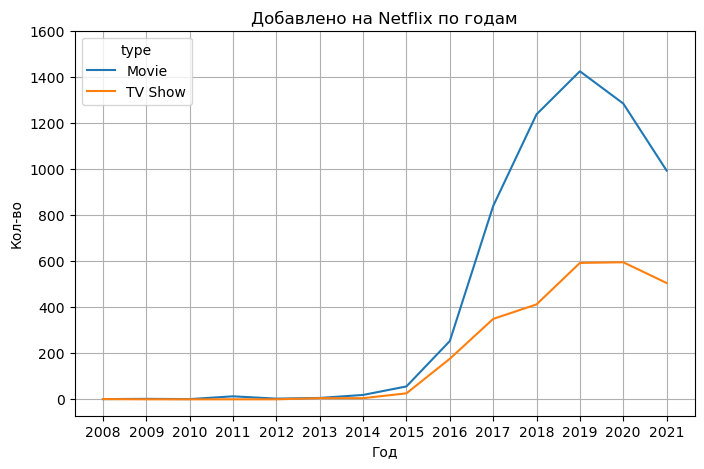

In [4]:
by_year.plot(title = 'Добавлено на Netflix по годам', xlabel = 'Год', ylabel = 'Кол-во',
                                                      xticks = by_year.index, yticks = range(0, 1601, 200),
                                                      grid = True, figsize = (8, 5));

In [5]:
df['date_added'].max()

Timestamp('2021-09-25 00:00:00')

**Вывод:**</br>
</br>
**1. Начало роста и пик** </br>
Рост начался в 2015 году, резкий рост в 2016, пик был в 2019 году </br>
**2. Преобладание** </br>
Практически на всём промежутке фильмов добавляется больше, чем сериалов, особенно после 2016 </br>
**3. Снижение** </br>
Снижение у фильмов началось после пика 2019 года, в 2020 году оно уже есть. Данные за 2021 неполные (до 25 сентября), поэтому нельзя сказать, что снижение в 2021 полное

## Вопрос 2. Какие страны дают больше всего контента?

In [6]:
df['country_list'] = df['country'].str.split(', ')
df_country = df.explode('country_list')

df_country['country_list'].value_counts().head()

country_list
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Name: count, dtype: int64

In [7]:
movies = df_country[df_country.type == 'Movie']
m = movies['country_list'].value_counts().head(10)
print(f'Movies: \n {m} \n')

series = df_country[df_country.type == 'TV Show']
s = series['country_list'].value_counts().head(10)
print(f'TV Shows: \n {s}')

Movies: 
 country_list
United States     2751
India              962
United Kingdom     532
Canada             319
France             303
Germany            182
Spain              171
Japan              119
China              114
Mexico             111
Name: count, dtype: int64 

TV Shows: 
 country_list
United States     938
United Kingdom    272
Japan             199
South Korea       170
Canada            126
France             90
India              84
Taiwan             70
Australia          66
Spain              61
Name: count, dtype: int64


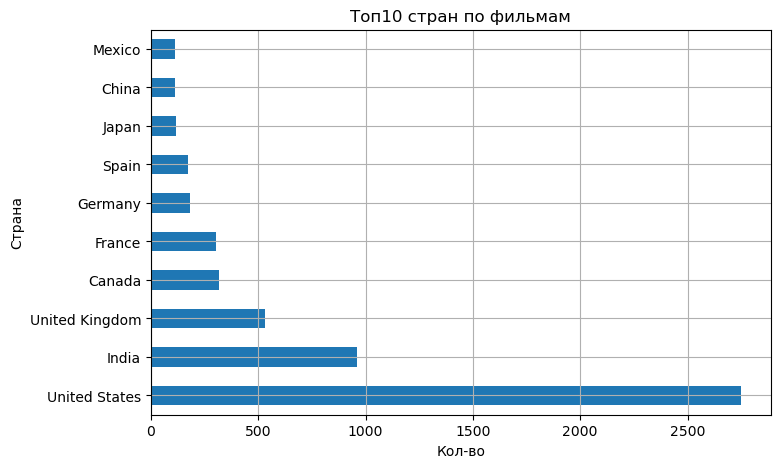

In [8]:
m.plot(kind = 'barh', title = 'Топ10 стран по фильмам',
                      xlabel = 'Кол-во', ylabel = 'Страна',
                      grid = True, figsize = (8, 5));

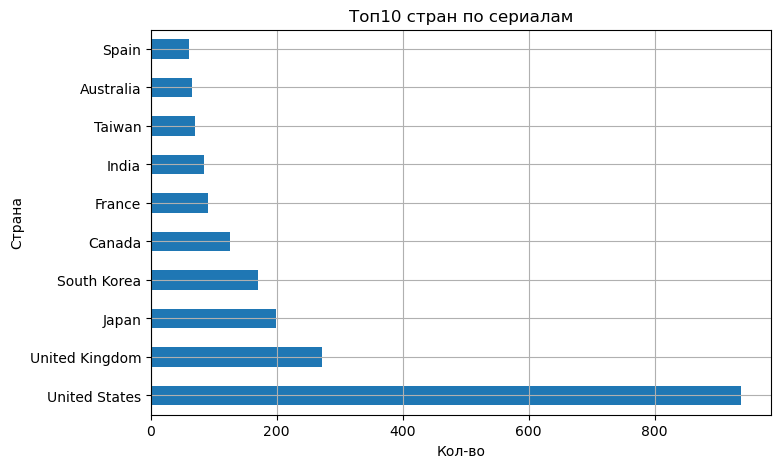

In [9]:
s.plot(kind = 'barh', title = 'Топ10 стран по сериалам', 
                      xlabel = 'Кол-во', ylabel = 'Страна',
                      grid = True, figsize = (8, 5));

**Вывод** </br>
Больше всего контента делают США - как в фильмах, так и в сериалах. Индия сильна в фильмах (топ2), однако в сериалах не очень (топ7). Великобритания, наоборот, сильнее в сериалах (топ2), и в фильмах тоже хороша (топ3)

## Вопрос 3. Какие жанры самые частые?

In [10]:
df['genre_list'] = df['listed_in'].str.split(', ')
df_genre = df.explode('genre_list')

g = df_genre['genre_list'].value_counts().head(10)
print(f'Частые жанры: \n {g} \n')

Частые жанры: 
 genre_list
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64 



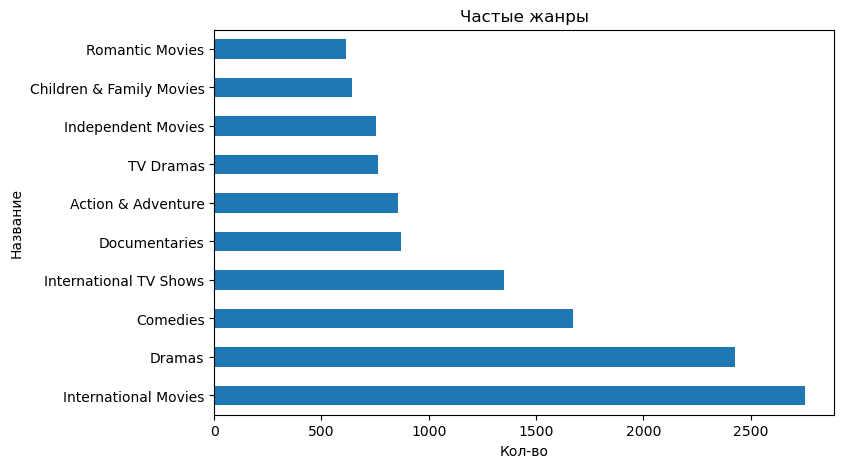

In [11]:
g.plot(kind = 'barh', title = 'Частые жанры',
                     xlabel = 'Кол-во', ylabel = 'Название',
                     figsize = (8, 5));

**Вывод** </br>
Самыми частыми жанрами являются - International Movies, Dramas, Comedies

## Вопрос 4. Сколько в данных пропусков и как они влияют на выводы?

In [12]:
columns = df.iloc[:, :12]
nan = columns.isna().sum()
nan[nan > 0]

director      2634
cast           825
country        831
date_added      10
rating           4
duration         3
dtype: int64

In [13]:
((nan[nan > 0] / len(df)) * 100).round(1)

director      29.9
cast           9.4
country        9.4
date_added     0.1
rating         0.0
duration       0.0
dtype: float64

**Вывод** </br>
Больше всего пропусков у колонки `director` - данных нет почти у 1/3 тайтлов (29.9%). </br>
В `cast` и `country` - пропуски по 9,4%, в остальных колонках пропусков почти нет. </br>
Из-за пропусков в `country` около 9% тайтлов не попало в подсчёт по странам, поэтому значения в вопросе 2 могут быть чуть занижены, но лидеры остались бы теми же, скорее всего. </br>
На вопросы 1 и 3 пропуски почти не повлияли.

## Общий вывод
В общем, с начала роста в 2015 году среди всего кино лидер - США. </br>
Самыми частыми жанрами являются международные фильмы, драмы и комедии. </br>
Однако для точности мешают пропуски, не очень критично, но всё же они есть